# Desafio 3 — Segmentação de clientes

Agrupar a base em grupos naturais para a mensagem da campanha. Entram só `Renda`, `Investimentos`, `Score_Credito`, `Gasto_Mensal_Cartao` e `Dividas`. Idade, escolaridade, emprego, dependentes, estado civil, identificadores e `Categoria_Cliente` ficam de fora: a segmentação olha o comportamento financeiro, sem copiar o rótulo oficial.


In [1]:
import optuna
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
SEMENTE = 42
COLUNAS = [
    "Renda",
    "Investimentos",
    "Score_Credito",
    "Gasto_Mensal_Cartao",
    "Dividas",
]


## Exploração

Histogramas, boxplots e a correlação usam só as cinco colunas. Os boxplots mostram a cauda de renda, investimento e dívida. Essa cauda faz parte do comportamento que a campanha quer enxergar, então os pontos permanecem na base.


In [2]:
base = pd.read_csv("datasets/clientes.csv")
features = base[COLUNAS].copy()
display(features.head())
display(features.describe())


,Renda,Investimentos,Score_Credito,Gasto_Mensal_Cartao,Dividas
0,3530.80,882.43,210,451.73,17089.75
1,6087.50,6989.56,482,1569.73,6537.04
2,3249.91,6300.54,585,468.87,1169.29
3,3709.71,12161.10,661,442.77,1433.53
4,11635.89,8030.33,351,1457.27,39111.05


,Renda,Investimentos,Score_Credito,Gasto_Mensal_Cartao,Dividas
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,7607.712285,43115.564090,577.743000,1638.345210,11977.963435
std,2912.175650,63476.727346,256.468402,986.718718,12783.020918
min,1100.000000,68.980000,0.000000,136.740000,457.320000
25%,5403.947500,5338.372500,371.000000,932.612500,3305.862500
50%,7508.235000,16283.300000,578.500000,1380.035000,6690.870000
75%,9647.935000,55160.980000,783.000000,2091.642500,16129.487500
max,17429.410000,747759.240000,1000.000000,6148.340000,89608.390000


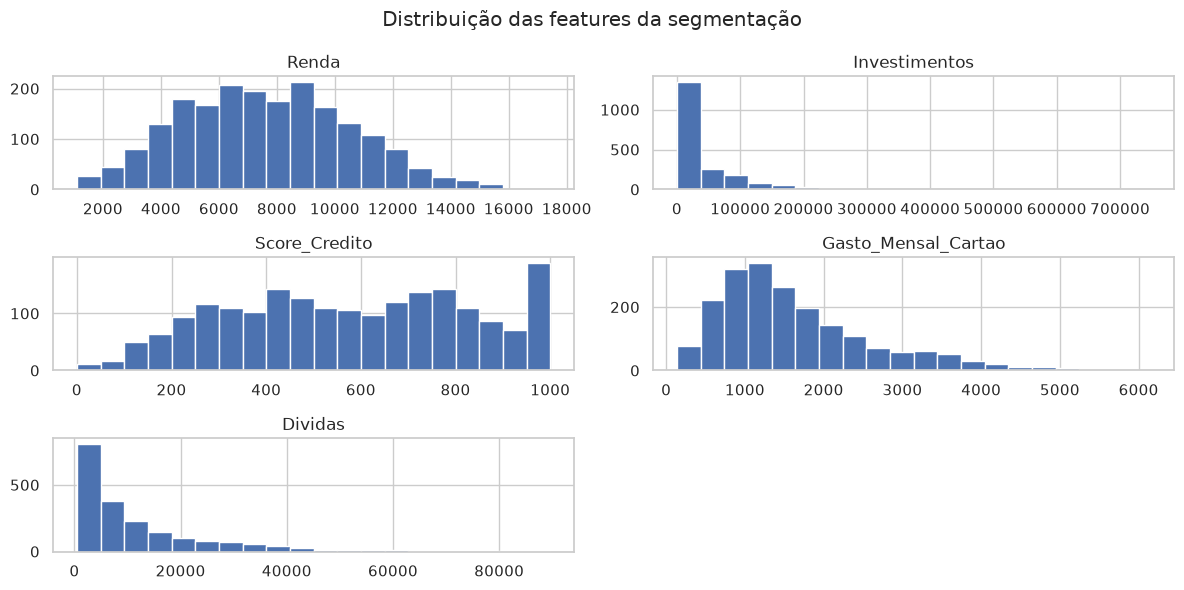

In [3]:
features.hist(figsize=(12, 6), bins=20)
plt.suptitle("Distribuição das features da segmentação")
plt.tight_layout()
plt.show()


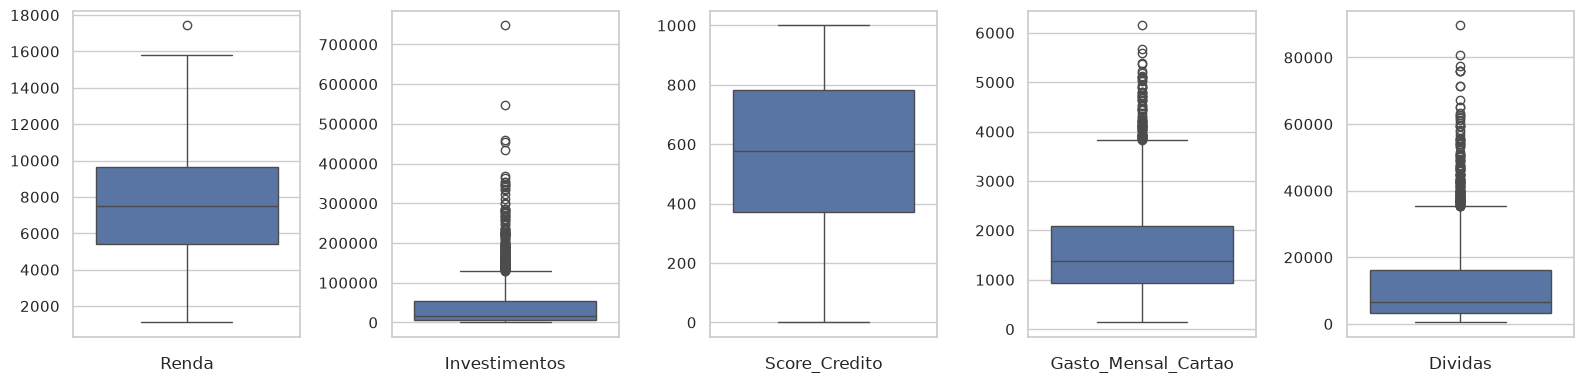

In [4]:
fig, eixos = plt.subplots(1, 5, figsize=(16, 4))
for eixo, coluna in zip(eixos, COLUNAS):
    sns.boxplot(y=features[coluna], ax=eixo)
    eixo.set_xlabel(coluna)
    eixo.set_ylabel("")
plt.tight_layout()
plt.show()


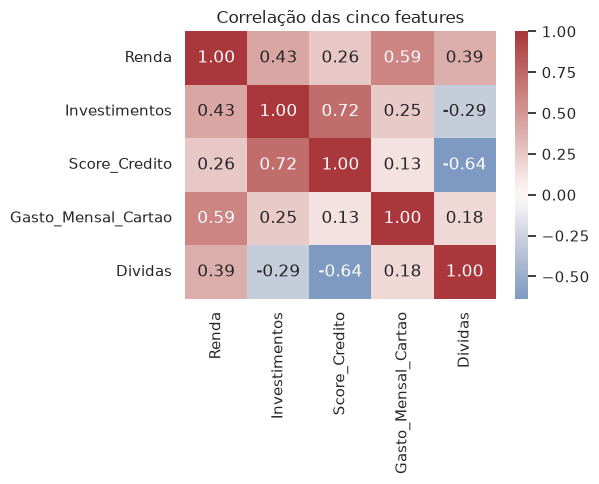

In [5]:
plt.figure(figsize=(6, 5))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlação das cinco features")
plt.tight_layout()
plt.show()


## Busca de k e modelo final

Não há split. O produto é a segmentação dos 2.000 clientes atuais, então o pipeline é ajustado na base inteira. O `ColumnTransformer` aplica `StandardScaler` nas cinco colunas. K-Means e silhouette usam distância euclidiana, e o silhouette é calculado na matriz já escalada.

A busca é um `GridSampler` com `n_clusters` de 2 a 10. O estudo maximiza o `silhouette_score`. O arquivo salvo é o pipeline inteiro, preprocessor e K-Means. O PCA vem depois e não entra nesse arquivo.


In [6]:
def criar_preprocessor():
    return ColumnTransformer(
        transformers=[("numericas", StandardScaler(), COLUNAS)]
    )


def objetivo(trial):
    n_clusters = trial.suggest_int("n_clusters", 2, 10)
    pipeline = Pipeline(
        steps=[
            ("preprocessor", criar_preprocessor()),
            (
                "kmeans",
                KMeans(n_clusters=n_clusters, n_init=10, random_state=SEMENTE),
            ),
        ]
    )
    rotulos = pipeline.fit_predict(features)
    matriz_escalada = pipeline.named_steps["preprocessor"].transform(features)
    return silhouette_score(matriz_escalada, rotulos)


estudo = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.GridSampler({"n_clusters": list(range(2, 11))}),
)
estudo.optimize(objetivo, n_trials=9)

melhor_k = int(estudo.best_params["n_clusters"])
melhor_silhouette = float(estudo.best_value)
print(f"Melhor k: {melhor_k}")
print(f"silhouette_score: {melhor_silhouette:.3f}")
display(
    estudo.trials_dataframe()[["params_n_clusters", "value"]]
    .rename(columns={"params_n_clusters": "k", "value": "silhouette"})
    .sort_values("k")
    .reset_index(drop=True)
)


Melhor k: 4
silhouette_score: 0.393


,k,silhouette
0,2,0.324826
1,3,0.347909
2,4,0.392712
3,5,0.377643
4,6,0.375486
5,7,0.377223
6,8,0.371616
7,9,0.346701
8,10,0.350071


In [7]:
modelo_segmentacao = Pipeline(
    steps=[
        ("preprocessor", criar_preprocessor()),
        ("kmeans", KMeans(n_clusters=melhor_k, n_init=10, random_state=SEMENTE)),
    ]
)
rotulos = modelo_segmentacao.fit_predict(features)
joblib.dump(modelo_segmentacao, "modelo_segmentacao.pkl")


['modelo_segmentacao.pkl']

## Perfil dos clusters

A média de cada feature, a contagem e o percentual saem do `groupby`. O nome de negócio usa o perfil padronizado entre os clusters: a feature com maior destaque dá o nome. Premium é patrimônio, Risco é dívida e Alto gasto é o cartão. O grupo de menor renda, quando nenhuma dessas três se destaca no positivo, fica como Conservador.


In [8]:
def nomear_clusters(medias):
    padrao = (medias - medias.mean()) / medias.std(ddof=0)
    nomes = {}
    for cluster, linha in padrao.iterrows():
        destaque = linha.idxmax()
        if destaque == "Investimentos" and linha[destaque] > 0.8:
            nomes[cluster] = "Premium"
        elif destaque == "Dividas" and linha[destaque] > 0.8:
            nomes[cluster] = "Risco"
        elif destaque == "Gasto_Mensal_Cartao" and linha[destaque] > 0.8:
            nomes[cluster] = "Alto gasto"
        elif linha["Renda"] == padrao["Renda"].min():
            nomes[cluster] = "Conservador"
        else:
            nomes[cluster] = f"Grupo {cluster}"
    return pd.Series(nomes, name="nome")


agrupado = features.copy()
agrupado["cluster"] = rotulos
medias = agrupado.groupby("cluster")[COLUNAS].mean()
contagem = agrupado.groupby("cluster").size().rename("contagem")
percentual = (contagem / len(agrupado) * 100).rename("percentual")
perfil = medias.join(contagem).join(percentual)
perfil = perfil.join(nomear_clusters(medias))
display(perfil.round(2))


,Renda,Investimentos,Score_Credito,Gasto_Mensal_Cartao,Dividas,contagem,percentual,nome
cluster,,,,,,,,
0,5131.62,19837.51,556.04,1035.34,5527.13,868,43.40,Conservador
1,9848.50,131910.61,905.54,1835.83,4951.61,465,23.25,Premium
2,9096.21,5838.27,262.29,1375.74,34085.88,359,17.95,Risco
3,9467.80,18109.73,511.71,3345.66,14996.89,308,15.40,Alto gasto


## Visualização

O PCA reduz as cinco features já escaladas a duas dimensões e colore os pontos pelo cluster. Ele serve só para leitura. O gráfico seguinte compara o perfil padronizado, porque renda, score e dívida não compartilham a mesma unidade.


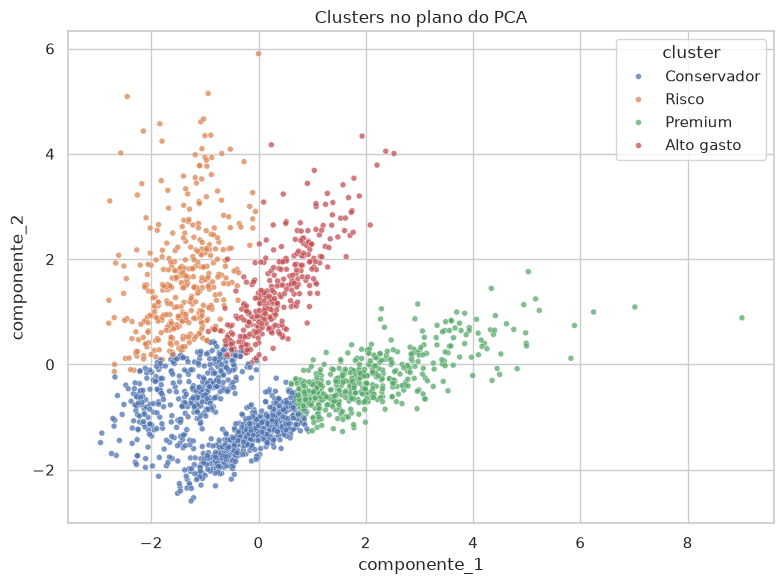

In [9]:
matriz_escalada = modelo_segmentacao.named_steps["preprocessor"].transform(features)
projecao = PCA(n_components=2, random_state=SEMENTE).fit_transform(matriz_escalada)
plano = pd.DataFrame(projecao, columns=["componente_1", "componente_2"])
plano["cluster"] = perfil.loc[rotulos, "nome"].to_numpy()

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plano,
    x="componente_1",
    y="componente_2",
    hue="cluster",
    s=18,
    alpha=0.75,
)
plt.title("Clusters no plano do PCA")
plt.tight_layout()
plt.show()


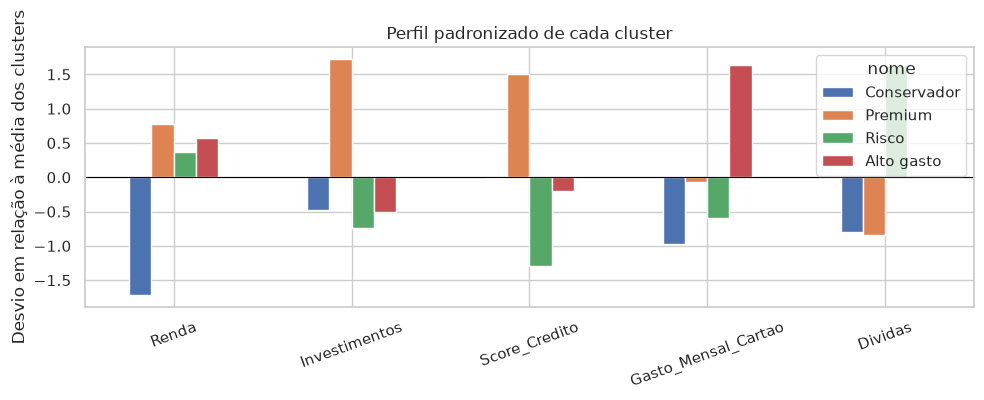

In [10]:
padrao = (medias - medias.mean()) / medias.std(ddof=0)
padrao.index = perfil["nome"]
padrao.T.plot(kind="bar", figsize=(10, 4), rot=20)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Desvio em relação à média dos clusters")
plt.title("Perfil padronizado de cada cluster")
plt.tight_layout()
plt.show()


## Conclusões

A referência é silhouette de pelo menos 0,18 e `k` entre 3 e 6.


In [11]:
print(f"Melhor k: {melhor_k}. silhouette_score: {melhor_silhouette:.3f}.")
print("Perfil de cada cluster:")
display(perfil.round(2))
for cluster, linha in perfil.iterrows():
    print(
        f"{linha['nome']} (cluster {cluster}): "
        f"{linha['contagem']:.0f} clientes ({linha['percentual']:.1f}%). "
        f"Renda média R$ {linha['Renda']:,.0f}, "
        f"investimentos R$ {linha['Investimentos']:,.0f}, "
        f"score {linha['Score_Credito']:.0f}, "
        f"gasto no cartão R$ {linha['Gasto_Mensal_Cartao']:,.0f}, "
        f"dívidas R$ {linha['Dividas']:,.0f}."
    )


Melhor k: 4. silhouette_score: 0.393.
Perfil de cada cluster:


,Renda,Investimentos,Score_Credito,Gasto_Mensal_Cartao,Dividas,contagem,percentual,nome
cluster,,,,,,,,
0,5131.62,19837.51,556.04,1035.34,5527.13,868,43.40,Conservador
1,9848.50,131910.61,905.54,1835.83,4951.61,465,23.25,Premium
2,9096.21,5838.27,262.29,1375.74,34085.88,359,17.95,Risco
3,9467.80,18109.73,511.71,3345.66,14996.89,308,15.40,Alto gasto


Conservador (cluster 0): 868 clientes (43.4%). Renda média R$ 5,132, investimentos R$ 19,838, score 556, gasto no cartão R$ 1,035, dívidas R$ 5,527.
Premium (cluster 1): 465 clientes (23.2%). Renda média R$ 9,849, investimentos R$ 131,911, score 906, gasto no cartão R$ 1,836, dívidas R$ 4,952.
Risco (cluster 2): 359 clientes (17.9%). Renda média R$ 9,096, investimentos R$ 5,838, score 262, gasto no cartão R$ 1,376, dívidas R$ 34,086.
Alto gasto (cluster 3): 308 clientes (15.4%). Renda média R$ 9,468, investimentos R$ 18,110, score 512, gasto no cartão R$ 3,346, dívidas R$ 14,997.
